# 06 — Production RAG: Hybrid Retrieval & Grounding Audit

Interactive analysis of the `bitext` customer-support policy corpus, BM25 vs. Vector vs. Hybrid RRF (`k=60`) ablation, RRF `k` sensitivity sweep, and abstention score distribution.

In [1]:
import sys
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT_DIR = next(p for p in [cwd, *cwd.parents] if (p / "feature_contract.json").exists())
ML_DIR = ROOT_DIR / "ml"
ARTIFACTS_DIR = ROOT_DIR / "artifacts"
PLOTS_DIR = ARTIFACTS_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

from train import (
    BM25Index,
    VectorIndex,
    fuse_rrf,
    load_contract,
    load_bitext_dataframe,
    build_policy_corpus_and_queries,
    evaluate,
)

contract, schema_hash = load_contract()
summary_df = pd.DataFrame(json.loads((ARTIFACTS_DIR / "eval_summary.json").read_text()))
corpus = [json.loads(line) for line in (ARTIFACTS_DIR / "corpus.jsonl").read_text().splitlines() if line.strip()]
corpus_df = pd.DataFrame(corpus)

print(f"Contract: {contract['schema_version']} | Schema Hash: {schema_hash} | Chunks: {len(corpus_df)} | Tenants: {corpus_df['tenant_id'].nunique()}")
print(f"Saving plots to: {PLOTS_DIR}")
summary_df

Contract: v1.0.0 | Schema Hash: dd207803af0b | Chunks: 27 | Tenants: 11
Saving plots to: /home/gun/work/github.com/gunawanwijaya/apprentice/06-production-rag/artifacts/plots


,strategy,recall_at_5,mrr_at_5,exact_code_recall_at_5,paraphrase_recall_at_5,queries_evaluated
0,bm25_only,0.9185,0.7881,1.000,0.8981,135
1,vector_only,0.9852,0.7898,0.963,0.9907,135
2,hybrid_rrf,0.9926,0.8419,1.000,0.9907,135


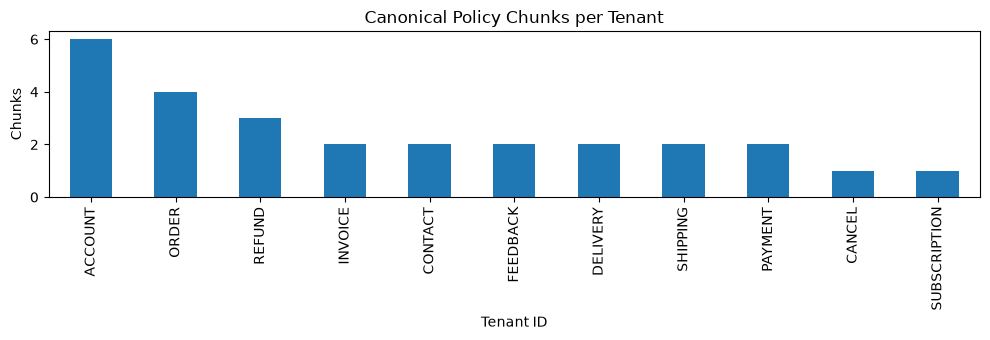

In [2]:
# 1. Tenant Policy Distribution
tenant_counts = corpus_df.groupby("tenant_id")["chunk_id"].count().sort_values(ascending=False)
ax = tenant_counts.plot(kind="bar", figsize=(10, 3.5), title="Canonical Policy Chunks per Tenant")
ax.set_ylabel("Chunks")
ax.set_xlabel("Tenant ID")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "01_tenant_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

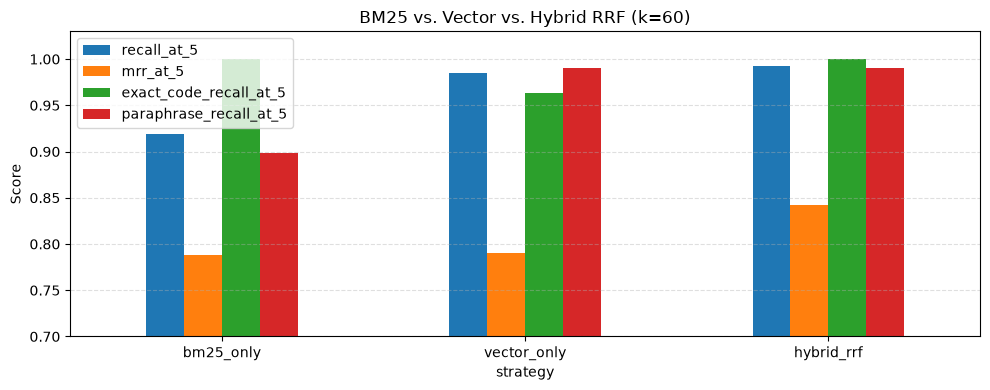

In [3]:
# 2. Retrieval Strategy Comparison (Recall@5, MRR@5, Exact-Code vs. Paraphrase)
plot_df = summary_df.set_index("strategy")[[
    "recall_at_5", "mrr_at_5", "exact_code_recall_at_5", "paraphrase_recall_at_5"
]]
ax = plot_df.plot(kind="bar", figsize=(10, 4), ylim=(0.70, 1.03), title="BM25 vs. Vector vs. Hybrid RRF (k=60)")
ax.set_ylabel("Score")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "02_retrieval_strategy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
# 3. RRF k Sensitivity Sweep (k in [10, 30, 60, 100])
df_raw = load_bitext_dataframe()
_, eval_queries = build_policy_corpus_and_queries(df_raw)
ret = contract["retrieval"]

bm25 = BM25Index(corpus, k1=ret["bm25_k1"], b=ret["bm25_b"])
vec = VectorIndex(corpus, dim=ret["embed_dim"])

sweep_rows = []
for k in (10, 30, 60, 100):
    res = evaluate(bm25, vec, eval_queries, rrf_k=k, top_k=ret["rerank_top_k"])
    hyb = next(r for r in res if r["strategy"] == "hybrid_rrf")
    sweep_rows.append({"rrf_k": k, "recall_at_5": hyb["recall_at_5"], "mrr_at_5": hyb["mrr_at_5"]})

pd.DataFrame(sweep_rows)

,rrf_k,recall_at_5,mrr_at_5
0,10,0.9926,0.8419
1,30,0.9926,0.8419
2,60,0.9926,0.8419
3,100,0.9926,0.8419


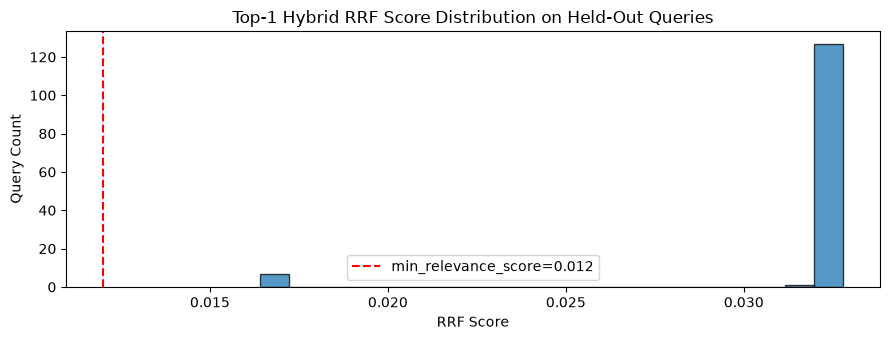

Saved plots: ['01_tenant_distribution.png', '02_retrieval_strategy_comparison.png', '03_rrf_score_distribution.png']


In [5]:
# 4. Top-1 RRF Score Distribution vs. Contract Abstention Threshold
top_scores = []
for q in eval_queries:
    b_hits = bm25.search(q["query"], q["tenant_id"], top_k=ret["bm25_top_k"])
    v_hits = vec.search(q["query"], q["tenant_id"], top_k=ret["vector_top_k"])
    h_hits = fuse_rrf(b_hits, v_hits, k=ret["rrf_k"])
    top_scores.append(h_hits[0][1] if h_hits else 0.0)

plt.figure(figsize=(9, 3.5))
plt.hist(top_scores, bins=20, edgecolor="black", alpha=0.75)
plt.axvline(ret["min_relevance_score"], color="red", linestyle="--", label=f"min_relevance_score={ret['min_relevance_score']}")
plt.title("Top-1 Hybrid RRF Score Distribution on Held-Out Queries")
plt.xlabel("RRF Score")
plt.ylabel("Query Count")
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "03_rrf_score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved plots:", sorted(p.name for p in PLOTS_DIR.glob("*.png")))